# **SEGUNDO EXAMEN PARCIAL**
### NOMBRE: Carlos Enrique Nieves Ochoa
### EXPEDIENTE: 758210
### FECHA: 5 de Noviembre de 2026

## **EJERCICIO 1**

Se tiene la siguiente función:

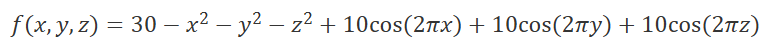

con dominio 

Utiliza optimización bayesiana para encontrar el valor máximo con las siguientes restricciones:
- 1. Empezar con 5 muestras aleatorias dentro del dominio.
- 2. Los primeros 10 pasos adicionales deben ser de exploración.
- 3. Después de los 10 pasos de exploración, se debe empezar a maximizar.

In [112]:
# Librerías
import pandas as pd
import numpy as np

In [113]:
# Definir la función objetivo
def f(x, y, z):
    return 30 - x**2 - y**2 - z**2 + 10*np.cos(2*np.pi*x) + 10*np.cos(2*np.pi*y) + 10*np.cos(2*np.pi*z)

# Definir el dominio
domain = [-5.12, 5.12]

# Generar 5 muestras aleatorias iniciales
initial_samples = np.random.uniform(domain[0], domain[1], size=(5, 3))

# Evaluar la función en las muestras iniciales
initial_values = [f(x, y, z) for x, y, z in initial_samples]

print("Muestras iniciales:", initial_samples)
print("Valores iniciales:", initial_values)

# Los primeros 10 pasos adicionales deben ser de exploración
exploration_steps = 10
exploration_samples = np.random.uniform(domain[0], domain[1], size=(exploration_steps, 3))
exploration_values = [f(x, y, z) for x, y, z in exploration_samples]

print("Pasos de exploración:", exploration_samples)
print("Valores de exploración:", exploration_values)

# Después de los 10 pasos de exploración, se debe empezar a maximizar
maximization_samples = []
maximization_values = []
for _ in range(10):  # Suponiendo 10 pasos de maximización
    # Seleccionar el siguiente punto como el que tiene el mayor valor esperado
    # Aquí se usa una estrategia simple: muestrear aleatoriamente y elegir el mejor
    candidates = np.random.uniform(domain[0], domain[1], size=(100, 3))
    candidate_values = [f(x, y, z) for x, y, z in candidates]
    best_idx = np.argmax(candidate_values)
    maximization_samples.append(candidates[best_idx])
    maximization_values.append(candidate_values[best_idx])

print("Pasos de maximización:", maximization_samples)
print("Valores de maximización:", maximization_values)

# Valor máximo encontrado
all_values = initial_values + exploration_values + maximization_values
all_samples = np.vstack([initial_samples, exploration_samples, maximization_samples])
best_idx = np.argmax(all_values)
print("Mejor muestra encontrada:", all_samples[best_idx])
print("Valor máximo encontrado:", all_values[best_idx])


Muestras iniciales: [[-1.08721882  2.86513808  0.38412567]
 [ 3.80159333  0.55272447 -1.75431448]
 [-1.629007   -1.46760381  1.35990792]
 [ 4.94056805  1.58861206 -2.44939515]
 [ 4.93238464  2.24288866  0.59303022]]
Valores iniciales: [np.float64(28.15196196664769), np.float64(6.1647682148871965), np.float64(0.2889767675366306), np.float64(-11.61003094974911), np.float64(1.507328550799011)]
Pasos de exploración: [[ 3.62719058 -2.96251277 -4.08303004]
 [-0.54856882  4.89910104 -3.88817109]
 [-2.25837415  0.02014152  2.86925349]
 [ 3.78141785 -1.30793095  3.29381139]
 [ 2.09806114  2.16358923 -2.80734965]
 [-0.76753548 -4.3655344  -2.16986673]
 [-1.57945526 -0.31082627  2.5197534 ]
 [ 0.88753895  3.27807437 -2.00760684]
 [ 2.53644848  0.86034469 -0.94274491]
 [-2.12271397  1.26989818 -2.75844899]]
Valores de exploración: [np.float64(2.8164488839331288), np.float64(-3.269743582265935), np.float64(32.872037201855434), np.float64(-1.1759332809830996), np.float64(29.889402605369987), np.floa

## **EJERCICIO 2**

Utilizando el dataset **(reviews_peliculas.csv)**

Un productor quiere información a partir de los datos históricos de películas. Lo que el productor quiere saber si el hecho de que una película sea comedia o no, y el año en que salió, tiene un peso sobre si la película es considerada buena (calificación mayor a 7.5).

## EDA

### Exploración del archivo

In [ ]:
df = pd.read_csv("reviews_peliculas.csv")
print("Tamaño:", df.shape)
print(df.dtypes)
print(df.head())

Tamaño: (240, 5)
titulo                      str
genero                      str
anio_estreno                str
presupuesto_millones_usd    str
calificacion_publico        str
dtype: object
                  titulo           genero anio_estreno  \
0     La Última Estación  Ciencia ficción         2011   
1    Horizonte de Ceniza            Drama         2024   
2  El Jardín de los Ecos          Comedia         2024   
3      Noche de Mercurio           Terror         2009   
4     Cartas desde Orión       Documental         2023   

  presupuesto_millones_usd calificacion_publico  
0                    33.94                  7.1  
1                    22.44                  6.1  
2                     9.56                  5.8  
3                    51.95                  3.8  
4                    38.06                  7.1  


In [115]:
# Resumen general
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   titulo                    240 non-null    str  
 1   genero                    240 non-null    str  
 2   anio_estreno              240 non-null    str  
 3   presupuesto_millones_usd  237 non-null    str  
 4   calificacion_publico      238 non-null    str  
dtypes: str(5)
memory usage: 19.2 KB


,titulo,genero,anio_estreno,presupuesto_millones_usd,calificacion_publico
count,240,240,240,237,238
unique,240,15,26,231,40
top,La Última Estación,Drama,2024,32.04,6.4
freq,1,40,15,2,15


In [117]:
# Faltantes y duplicados
print(df.isna().sum())
print("Duplicados:", df.duplicated().sum())

titulo                      0
genero                      0
anio_estreno                0
presupuesto_millones_usd    3
calificacion_publico        2
dtype: int64
Duplicados: 0


In [119]:
# Revisar categorías de cada variable de texto
categorical_cols = ["titulo", "genero", "anio_estreno", "presupuesto_millones_usd", "calificacion_publico"]

for col in categorical_cols:
    print(col, df[col].unique())
    print("Número de categorías:", df[col].nunique())

titulo <ArrowStringArray>
[         'La Última Estación',         'Horizonte de Ceniza',
       'El Jardín de los Ecos',           'Noche de Mercurio',
          'Cartas desde Orión',         'La Ciudad Sumergida',
               'Código Aurora',             'Los Días de Sal',
       'El Tren de Medianoche',          'Bajo la Misma Luna',
 ...
           'Pájaros de Neón 8',  'El Mapa de los Recuerdos 8',
           'Frecuencia Cero 8',        'La Isla de Cristal 8',
 'Los Guardianes del Tiempo 8',    'Una Señal en la Niebla 8',
          'El Peso del Agua 8',  'La Máquina de los Sueños 8',
           'Verano en Marte 8',         'El Último Aplauso 8']
Length: 240, dtype: str
Número de categorías: 240
genero <ArrowStringArray>
['Ciencia ficción',           'Drama',         'Comedia',          'Terror',
      'Documental',          'Acción',         ' drama ',       'Animación',
 'CIENCIA FICCION',         'Romance',         'comedia',          'Accion',
         'Terrorr',        'Fant

### Inicio de correcciones

In [ ]:
df["presupuesto_millones_usd"] = df["presupuesto_millones_usd"].replace(",", ".", regex=True).astype(float)
df["presupuesto_millones_usd"].fillna(df["presupuesto_millones_usd"].median(), inplace=True)


C:\Users\carlo\AppData\Local\Temp\ipykernel_27928\3067499598.py:3: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df["presupuesto_millones_usd"].fillna(df["presupuesto_millones_usd"].median(), inplace=True)


0      33.94
1      22.44
2       9.56
3      51.95
4      38.06
       ...  
235    12.01
236     3.38
237    21.40
238     6.14
239    24.21
Name: presupuesto_millones_usd, Length: 240, dtype: float64

In [ ]:
df["calificacion_publico"] = df["calificacion_publico"].replace(",", ".", regex=True).astype(float)
df["calificacion_publico"].fillna(df["calificacion_publico"].median(), inplace=True)


C:\Users\carlo\AppData\Local\Temp\ipykernel_27928\2236649583.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df["calificacion_publico"].fillna(df["calificacion_publico"].median(), inplace=True)


0      7.1
1      6.1
2      5.8
3      3.8
4      7.1
      ... 
235    8.4
236    5.4
237    4.9
238    5.7
239    5.6
Name: calificacion_publico, Length: 240, dtype: float64